# LEDGAR — clause retrieval (milestone m2)

> **Summary**
> - Thirteen bank encodings compared on validation (TF-IDF, five off-the-shelf encoders raw and centred, the
>   fine-tuned classifier's features), each with five hybrid variants: 78 candidates. The initial all-pooled rule kept
>   **one**: TF-IDF cosine, dense (test macro P@10 **0.658**, validation 0.661, MRR 0.873, 10-NN vote macro-F1 0.737),
>   because pooling a bag-of-words baseline into a half-clause self-retrieval gate ($0.95 \times 0.897 = 0.852$)
>   structurally requires exact n-gram overlap.
> - Separating the lexical baseline from dense semantic encoders (`retrieval.choose_semantic`, within-type gate
>   $\text{MRR} \ge 0.95 \times 0.761 = 0.723$ and zero-shot NL floor $\text{P@10} \ge 0.50$) selects **`bge+center`
>   (`dense`)** for clause-to-clause similarity (**0.669** validation macro P@10, beating TF-IDF by **+0.76 pts**,
>   95 % CI [+0.27, +1.21], and by **+1.85 pts macro / +4.64 pts micro** on the low-lexical-overlap quartile) and
>   **`e5` (`dense`)** for natural-language lawyer questions (**86.2 %** constraint precision, 4.0× lift, **0.591**
>   type-name P@10).
> - The classifier's features win the type proxy (P@10 0.758) and lose the clause (MRR 0.508): the neural collapse
>   predicted in the README. Every hybrid variant reaches P@10 0.80-0.81 whatever the encoder, because that is the
>   classifier's accuracy, and loses 8 to 28 points of within-type MRR against its own dense variant: the type
>   should be a filter the lawyer ticks, not one the classifier guesses.

Given a pasted clause or a lawyer's question, the retriever returns the most similar clauses of a clause bank
(the 60 000 training clauses). The runs were made by `scripts/retrieval.py` (one encoder at a time, validation
only), the configuration was chosen by `scripts/retrieval.py --choose`, and the test split was
read once (`--final`). This notebook reads the saved runs and checks a few things live on the data.

## Setup

In [1]:
# Colab: clone the repository and install the package when `ledgar` is not importable (a no-op elsewhere).
import importlib.util
import os
import subprocess
import sys

if importlib.util.find_spec("ledgar") is None:
    repo, url = "/content/nlp-project", "https://github.com/jbouniol/nlp-project.git"
    if not os.path.isdir(repo):
        subprocess.run(["git", "clone", "-q", "-b", "main", url, repo], check=True)
    os.chdir(repo)
    pins = "transformers==5.19.0 datasets==5.1.0 huggingface-hub==1.33.0 accelerate==1.15.0 peft==0.21.2"
    pins += " scikit-learn==1.9.1 sentence-transformers==6.1.0"  # Colab keeps its own torch (colab/run_m4)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pins.split()], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".", "--no-deps"], check=True)
    sys.path.insert(0, os.path.join(repo, "src"))
    importlib.invalidate_caches()

In [2]:
import json
import re
import warnings
from dataclasses import replace

warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub.utils import logging as hub_logging

from ledgar import data, retrieval
from ledgar.config import Config, set_seed
from ledgar.retrieval import Index

hub_logging.set_verbosity_error()
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

cfg = Config.from_env()
set_seed(cfg.seed)
RESULTS, FIGURES = cfg.path("results", "retrieval"), cfg.path(cfg.reports_dir, "figures")
ledgar = data.load_ledgar(cfg)
LABELS = data.label_names(ledgar)
bank_texts, y_bank = ledgar["train"]["text"], np.array(ledgar["train"]["label"])
val_texts, y_val = ledgar["validation"]["text"], np.array(ledgar["validation"]["label"])
METRICS = {p.parent.name: json.loads(p.read_text()) for p in sorted(RESULTS.glob("*/metrics.json"))}
assert METRICS, "no retrieval run under results/retrieval: run `make m2` first"
table = retrieval.retrieval_table(RESULTS).set_index("run")
print(cfg)
print(f"{len(METRICS)} runs: {', '.join(METRICS)}")

fast_run=False | seed=0 | device=mps | precision=fp32 | batch_size=8 | grad_accum=4 | model_name=distilbert-base-uncased | max_length=512 | max_words=476 | epochs=10
13 runs: bge, bge+center, classifier:lora_lr1e-3_ep10_seed0, classifier:lora_lr1e-3_ep10_seed0+center, distilbert, distilbert+center, e5, e5+center, legalbert, legalbert+center, minilm, minilm+center, tfidf


## 1. The bank, the queries, and what "similar" means

Bank = the 60 000 training clauses; queries = the 10 000 validation clauses; the test split is read once at the
end. The only label we have is the clause type, so a retrieved clause counts as *relevant* when it has the type
of the query: $P@k$ is the share of the top-$k$ with the right type, MRR the reciprocal rank of the first one,
both averaged over types (macro, as for the classifiers). That proxy measures the type, not the wording inside a
type, which is what a lawyer actually compares. Two checks look inside a type: a degraded copy of a clause must
retrieve its source (section 4), and lawyer questions with a verifiable constraint ("a 30-day notice") are graded
by a regex on the retrieved texts.

In [3]:
counts = np.bincount(y_bank, minlength=cfg.n_classes)
share = counts / counts.sum()
floor = pd.Series(
    {
        "bank clauses": int(counts.sum()),
        "validation queries": len(y_val),
        "clause types in the bank": int((counts > 0).sum()),
        "random P@10, micro (sum of squared type shares)": float(share @ share),
        "random P@10, macro (mean type share)": float(share[counts > 0].mean()),
        "validation clauses with an exact copy in the bank": float(
            data.seen_in_train(ledgar, "validation").mean()
        ),
    }
)
questions = pd.DataFrame([q.__dict__ for q in retrieval.CONSTRAINED_QUERIES]).drop(columns="example")
display(floor.to_frame("value"))
questions

,value
bank clauses,60000.000000
validation queries,10000.000000
clause types in the bank,100.000000
"random P@10, micro (sum of squared type shares)",0.017965
"random P@10, macro (mean type share)",0.010000
validation clauses with an exact copy in the bank,0.027000


,question,target,pattern
0,termination clauses with a 30-day notice period,Terminations,thirty \(30\) days|30 days
1,governing law clause choosing New York law,Governing Laws,New York
2,governing law clause choosing Delaware law,Governing Laws,Delaware
3,assignment clause requiring the prior written consent of the other party,Assignments,prior written consent
4,agreement may be executed in counterparts delivered by electronic signature or facsimile,Counterparts,electronic|facsimile|pdf
5,indemnification clause covering reasonable attorneys' fees,Indemnifications,attorneys'? fees
6,confidentiality obligations surviving for two years after termination,Confidentiality,two \(2\) years|2 years|twenty-four \(24\) months
7,notices sent by email or electronic mail are effective,Notices,e-?mail|electronic mail
8,arbitration under the rules of the American Arbitration Association,Arbitration,American Arbitration Association|\bAAA\b
9,waiver of the right to a jury trial,Waiver Of Jury Trials,jury


→ **Consequence:** a retriever that ignores the text scores about 0.01 on macro P@10: every number below is measured
against that floor, not against 0. The questions above are the only "lawyer" queries we can grade without a
lawyer; their constraint is lexical (a notice period, a state, a word), and the regex is said to be crude.

## 2. Which encoder retrieves the right type? (validation)

Six off-the-shelf encoders, each also after centering on the bank mean, and the penultimate features of the
fine-tuned classifier when its run exists (`classifier:*`). The 10-nearest-neighbour vote is also scored as a
classifier (macro-F1), which puts the retriever on the scale of part 1.

In [4]:
cols = [
    "encoder",
    "centered",
    "p_at_1",
    "p_at_5",
    "p_at_10",
    "mrr_micro",
    "knn_macro_f1",
    "perturb_mrr",
    "type_names_p_at_10",
]
ranking = table[cols].sort_values("p_at_10", ascending=False)
best_run = ranking.index[0]
print(f"best macro P@10 on validation: {best_run} ({ranking.iloc[0]['p_at_10']:.4f})")
ranking.round(4)

best macro P@10 on validation: classifier:lora_lr1e-3_ep10_seed0 (0.7576)


,encoder,centered,p_at_1,p_at_5,p_at_10,mrr_micro,knn_macro_f1,perturb_mrr,type_names_p_at_10
run,,,,,,,,,
classifier:lora_lr1e-3_ep10_seed0,classifier:lora_lr1e-3_ep10_seed0,False,0.8159,0.7742,0.7576,0.8969,0.7903,0.5079,0.655
classifier:lora_lr1e-3_ep10_seed0+center,classifier:lora_lr1e-3_ep10_seed0,True,0.8152,0.7740,0.7576,0.8963,0.7905,0.5097,0.657
legalbert+center,legalbert,True,0.7793,0.7113,0.6741,0.8794,0.7456,0.6898,0.024
bge+center,bge,True,0.7718,0.7020,0.6689,0.8783,0.7381,0.7422,0.540
legalbert,legalbert,False,0.7765,0.7037,0.6677,0.8780,0.7433,0.6939,0.030
tfidf,tfidf,False,0.7765,0.6988,0.6614,0.8728,0.7431,0.8973,0.481
bge,bge,False,0.7688,0.6935,0.6591,0.8765,0.7317,0.7487,0.558
e5,e5,False,0.7592,0.6821,0.6483,0.8699,0.7289,0.7612,0.591
e5+center,e5,True,0.7411,0.6677,0.6322,0.8568,0.7269,0.7458,0.538


,head,middle,tail,not in train,truncated
classifier:lora_lr1e-3_ep10_seed0,0.9100,0.7932,0.5366,0.7557,0.8356
legalbert,0.8489,0.7078,0.4115,0.6661,0.6996
tfidf,0.8295,0.6986,0.4233,0.6598,NaN
bge,0.8545,0.6967,0.3992,0.6572,0.7195
e5,0.8447,0.6861,0.3871,0.6465,0.6450
minilm,0.8243,0.6571,0.3660,0.6206,0.5969
distilbert,0.7936,0.6404,0.3609,0.6032,0.5838


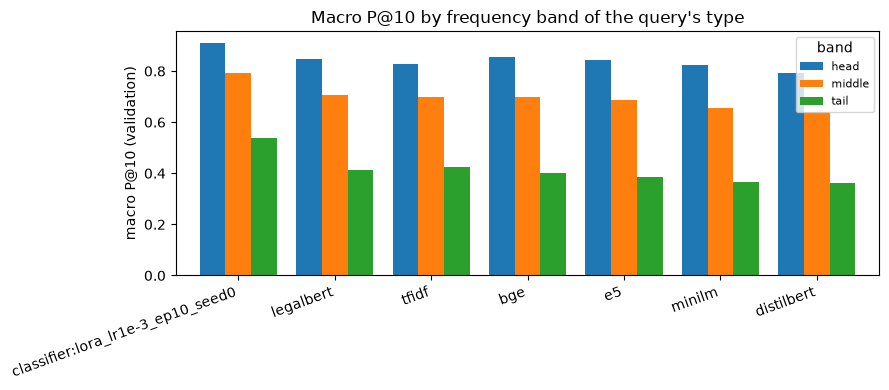

In [5]:
bands = ["band=head", "band=middle", "band=tail"]
rows = {
    run: {b.split("=")[1]: m["val"]["by_group"].get(b, {}).get("p_at_10_macro", np.nan) for b in bands}
    | {"not in train": m["val"]["by_group"].get("seen_in_train=False", {}).get("p_at_10_macro", np.nan)}
    | {"truncated": m["val"]["by_group"].get("truncated=True", {}).get("p_at_10_macro", np.nan)}
    for run, m in METRICS.items()
    if not m["centered"]
}
by_group = pd.DataFrame(rows).T.loc[lambda d: d.index.isin(ranking.index)]
by_group = by_group.loc[ranking.index.intersection(by_group.index)]
fig, ax = plt.subplots(figsize=(9, 4))
by_group[["head", "middle", "tail"]].plot.bar(ax=ax, width=0.8)
ax.set(ylabel="macro P@10 (validation)", title="Macro P@10 by frequency band of the query's type", xlabel="")
ax.legend(title="band", fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
if not cfg.fast_run:
    fig.savefig(FIGURES / "retrieval_p10_bands.png", dpi=150)
by_group.round(4)

→ **Consequence:** on the type proxy the encoders sit within seven points of each other: Legal-BERT centred 0.674,
bge centred 0.669, TF-IDF 0.661, e5 0.648, MiniLM 0.630, DistilBERT 0.616; the classifier's own features reach
0.758. Every encoder loses 40 points between the head and the tail of the type distribution and 12 points on
clauses that have no exact copy in the bank. Truncation costs little: 1.8 % of clauses exceed 512 wordpieces, and
MiniLM, which cuts 13.5 % at 256, loses 2.5 points on them. The 10-NN vote is a weaker classifier than the
logistic regression of part 1 (0.743 against 0.827 macro-F1), as expected from a non-parametric vote over 60 000
clauses. None of this separates the encoders; the within-type checks of section 4 do.

## 3. Why: the geometry of the bank embeddings

Five numbers on the 60 000 bank vectors of each encoder. **Anisotropy**: mean cosine between random pairs (0 for
an isotropic cloud, close to 1 in a narrow cone, Ethayarajh 2019). **Effective rank**: $\exp H(\sigma / \sum
\sigma)$ of the singular values (Roy & Vetterli 2007), how many directions carry signal. **Hubness**: skewness of
$N_{10}$, the number of top-10 lists each clause appears in (Radovanović et al. 2010). **Alignment** (mean cosine
of same-type pairs) and **uniformity** ($\log \mathbb{E}\, e^{-2\|u-v\|^2}$, lower is more spread) of Wang &
Isola 2020. Centering subtracts the bank mean: the one-line fix for a cone.

,p_at_10,anisotropy,effective_rank,hubness_skew,hubness_max_share,alignment,uniformity
run,,,,,,,
classifier:lora_lr1e-3_ep10_seed0,0.758,0.177,557.409,1.760,0.000,0.581,-3.168
classifier:lora_lr1e-3_ep10_seed0+center,0.758,-0.000,578.568,1.772,0.000,0.492,-3.798
legalbert+center,0.674,0.001,470.969,1.422,0.000,0.394,-3.696
bge+center,0.669,-0.000,305.853,2.026,0.000,0.297,-3.849
legalbert,0.668,0.796,338.903,1.744,0.000,0.878,-0.787
tfidf,0.661,0.029,NaN,4.709,0.001,0.116,-3.875
bge,0.659,0.617,258.893,2.059,0.000,0.731,-1.495
e5,0.648,0.821,229.070,1.937,0.000,0.871,-0.710
e5+center,0.632,-0.000,314.812,1.905,0.000,0.278,-3.863


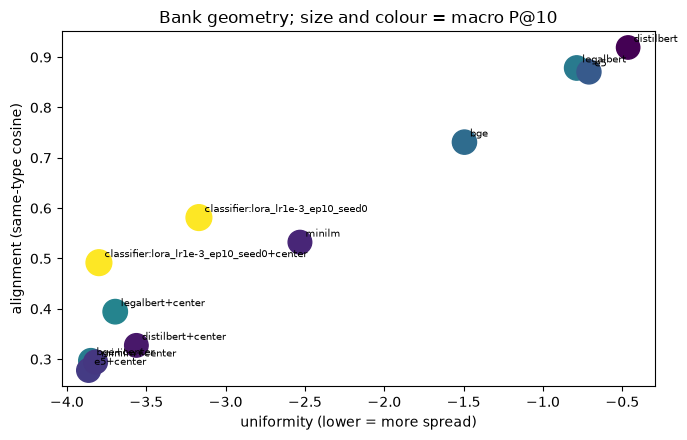

In [6]:
geo_cols = ["anisotropy", "effective_rank", "hubness_skew", "hubness_max_share", "alignment", "uniformity"]
geometry = pd.DataFrame({run: m["geometry"] for run, m in METRICS.items()}).T[geo_cols]
geometry.insert(0, "p_at_10", table["p_at_10"])
geometry = geometry.loc[ranking.index]
fig, ax = plt.subplots(figsize=(7, 4.5))
dense = geometry.dropna(subset=["effective_rank"])
ax.scatter(
    dense["uniformity"], dense["alignment"], s=40 + 400 * dense["p_at_10"], c=dense["p_at_10"], cmap="viridis"
)
for run, r in dense.iterrows():
    ax.annotate(run, (r["uniformity"], r["alignment"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set(
    xlabel="uniformity (lower = more spread)",
    ylabel="alignment (same-type cosine)",
    title="Bank geometry; size and colour = macro P@10",
)
fig.tight_layout()
if not cfg.fast_run:
    fig.savefig(FIGURES / "retrieval_geometry.png", dpi=150)
geometry.round(3)

In [7]:
full = data.load_ledgar(
    replace(cfg, n_train_per_class=None, n_eval_per_class=None)
)  # the runs saw the whole bank
keys = pd.Series([data.normalise(t) for t in full["train"]["text"]])
choice_path = RESULTS / "choice.json"
shown = json.loads(choice_path.read_text())["run"] if choice_path.exists() else "tfidf"
hubs = pd.read_csv(RESULTS / shown / "hubs.csv")
hubs["type"] = [LABELS[k] for k in hubs["label"]]
hubs["copies in bank"] = [int((keys == keys.iloc[i]).sum()) for i in hubs["index"]]
print(f"the 10 largest hubs of the chosen run, {shown}")
hubs[["index", "type", "n_k", "copies in bank", "text"]]

the 10 largest hubs of the chosen run, tfidf


,index,type,n_k,copies in bank,text
0,30444,Integration,414,1,This Agreement constitutes the entire agreement between the parties with respect to th...
1,45561,Entire Agreements,300,1,This Agreement constitutes the entire agreement between the parties with respect to th...
2,34353,Entire Agreements,230,1,This Agreement constitutes the entire agreement between the parties with respect to th...
3,4920,Assigns,211,1,"Subject to Section 9.3 , infra, this Agreement shall be binding upon and inure to the ..."
4,46485,Governing Laws,192,1,"(a) This Agreement shall be governed by, and construed in accordance with, the laws of..."
5,53642,Entire Agreements,190,1,This Agreement constitutes the entire agreement between the parties hereto with respec...
6,29735,Governing Laws,186,1,"This Agreement shall be governed by and construed in accordance with, the laws of the ..."
7,23207,Entire Agreements,177,1,"This Agreement supersedes all prior agreements, written or oral, between the parties h..."
8,681,Survival,174,1,The provisions of this Section 9 shall survive the termination of this Agreement.
9,50720,Counterparts,174,1,"This Agreement may be executed in any number of counterparts, each of which shall be d..."


→ **Consequence:** the raw encoders live in a cone: mean cosine between *random* clauses 0.88 (DistilBERT), 0.82
(e5), 0.80 (Legal-BERT), 0.62 (bge), against 0.33 for MiniLM and 0.03 for TF-IDF. Their raw "alignment" of 0.87-0.92
is that cone, not type structure: after centring it falls to 0.28-0.39 and then tracks P@10 (Legal-BERT 0.39 first,
e5 0.28 last among the dense). Centring is worth about one point for bge, Legal-BERT, MiniLM and DistilBERT and
costs e5 1.6 points: e5 was trained with query/passage prefixes, and the mean it loses carries that asymmetry.
Hubness is the TF-IDF weakness: skewness 4.7 against 1.4-2.1 for the dense encoders, and the top hub, the boilerplate
"This Agreement constitutes the entire agreement between the parties...", sits in 414 of the 60 000 top-10 lists;
bge, DistilBERT and Legal-BERT share that boilerplate hub three to four times less often, MiniLM's and e5's
largest hubs are other types (Indemnifications, Terms, Base Salary).

## 4. Inside a type: a degraded clause must find its source, and lawyer questions must keep their constraint

**Perturbation.** 1 000 validation clauses with no copy in the bank, each cut to its first half, its second half,
or with one sentence removed. The degraded clause is the query; its source is scored like a bank clause; the rank
of the source among bank + source gives Hit@1 and MRR. A retriever that only knows the type cannot do this.
**Questions.** For each of the 18 questions: share of the top-10 with the target type, share of those that
satisfy the constraint, and the base rate of the constraint among the bank clauses of that type (lift =
precision / base rate).

In [8]:
pert = pd.DataFrame(
    {
        run: {"MRR": m["val"]["perturbation"]["mrr"], "Hit@1": m["val"]["perturbation"]["hit_at_1"]}
        | {f"MRR {v}": s["mrr"] for v, s in m["val"]["perturbation"]["views"].items()}
        for run, m in METRICS.items()
    }
).T.loc[ranking.index]
pert.round(4)

,MRR,Hit@1,MRR head,MRR tail,MRR drop_sentence
run,,,,,
classifier:lora_lr1e-3_ep10_seed0,0.5079,0.4227,0.6659,0.2612,0.7768
classifier:lora_lr1e-3_ep10_seed0+center,0.5097,0.4262,0.6659,0.2642,0.7806
legalbert+center,0.6898,0.6052,0.6352,0.6921,0.8479
bge+center,0.7422,0.6678,0.7898,0.6404,0.9068
legalbert,0.6939,0.6116,0.6392,0.6973,0.8493
tfidf,0.8973,0.8485,0.8639,0.9165,0.9400
bge,0.7487,0.6760,0.7911,0.6538,0.9077
e5,0.7612,0.6893,0.8111,0.6714,0.8825
e5+center,0.7458,0.6687,0.7987,0.6481,0.8817


In [9]:
for run in ("e5", "tfidf"):
    summary = METRICS[run]["val"]["constrained_summary"]
    print(f"{run}: " + ", ".join(f"{k} {v:.3f}" for k, v in summary.items() if k != "n"))
cq = pd.DataFrame(METRICS["e5"]["val"]["constrained"]).set_index("question")
cq_tfidf = pd.DataFrame(METRICS["tfidf"]["val"]["constrained"]).set_index("question")
cols = ["type_p_at_k", "constraint_precision", "lift"]
side = pd.concat({"e5": cq[cols], "tfidf": cq_tfidf[cols]}, axis=1)
side.insert(0, "base_rate", cq["base_rate"])
side.round(2)

e5: type_p_at_10 0.667, constraint_precision 0.862, lift 3.968
tfidf: type_p_at_10 0.594, constraint_precision 0.752, lift 3.266


base_rate  ...  tfidf
                                                                                                    ...   lift
question                                                                                            ...       
termination clauses with a 30-day notice period                                               0.04  ...  15.13
governing law clause choosing New York law                                                    0.32  ...   1.94
governing law clause choosing Delaware law                                                    0.19  ...   1.17
assignment clause requiring the prior written consent of the other party                      0.35  ...   2.84
agreement may be executed in counterparts delivered by electronic signature or facsimile      0.69  ...   1.17
indemnification clause covering reasonable attorneys' fees                                    0.05  ...    NaN
confidentiality obligations surviving for two years after termination                         0.00  ...    NaN
notices sent by email or electronic mail are effective                                        0.23  ...   4.00
arbitration under the rules of the American Arbitration Association                           0.57  ...   1.76
waiver of the right to a jury trial                                                           0.98  ...   1.02
severability clause                                                                            NaN  ...    NaN
entire agreement clause superseding all prior agreements                                      0.82  ...   1.21
payment clause charging interest on late payments                                             0.32  ...    NaN
non-disparagement clause                                                                       NaN  ...    NaN
insurance clause requiring a minimum coverage amount in dollars                               0.07  ...   9.56
withholding of taxes from payments to the employee                                            0.94  ...   1.06
change in control triggering accelerated vesting                                              0.47  ...   0.85
submission to the exclusive jurisdiction of the courts of New York                            0.66  ...   0.75

[18 rows x 7 columns]

In [10]:
# Live: the 30-day question, with and without the type the lawyer would tick (no classifier involved)
spec = retrieval.ENCODERS["minilm"]
encoder = retrieval.load_encoder(spec, cfg, bank_texts)
E_bank = retrieval.cached_embeddings(encoder, bank_texts, "train", "doc", cfg)
index = Index(E_bank, y_bank, np.arange(len(y_bank)), device=cfg.device)
question = retrieval.CONSTRAINED_QUERIES[0]
pattern = re.compile(question.pattern, flags=re.IGNORECASE)
q = encoder.encode([question.question], "nl")
manual = np.zeros((1, cfg.n_classes), dtype=np.float32)
manual[0, LABELS.index(question.target)] = 1.0


def show(positions, scores):
    return pd.DataFrame(
        {
            "score": scores[0].round(3),
            "type": [LABELS[y_bank[p]] for p in positions[0]],
            "30 days": [bool(pattern.search(bank_texts[p])) for p in positions[0]],
            "clause": [bank_texts[p][:110] + "…" for p in positions[0]],
        }
    )


scores_d, pos_d = index.search(q, 5)
scores_h, pos_h = index.search(q, 5, type_probs=manual, hard=True)
print(f"'{question.question}' — dense top-5, then restricted to {question.target}")
display(show(pos_d, scores_d))
show(pos_h, scores_h)

'termination clauses with a 30-day notice period' — dense top-5, then restricted to Terminations


,score,type,30 days,clause
0,0.751,Terminations,True,The Term of this Agreement may be terminated by either party upon thirty (30) days’ pr...
1,0.733,Notices,False,"In the event of an occurrence constituting the basis of termination for Cause, with th..."
2,0.729,Notices,True,"Notwithstanding the foregoing, it shall be a condition precedent to the Company’s righ..."
3,0.724,Terminations,True,You or the Company may terminate this Agreement without cause upon 30 days’ written no...
4,0.721,Terms,True,The term of this Agreement shall be for a period of ______ and shall be automatically ...


,score,type,30 days,clause
0,0.751,Terminations,True,The Term of this Agreement may be terminated by either party upon thirty (30) days’ pr...
1,0.724,Terminations,True,You or the Company may terminate this Agreement without cause upon 30 days’ written no...
2,0.714,Terminations,True,Either the Executive or the Company may terminate the Executive's employment under thi...
3,0.704,Terminations,True,The Company may terminate this Agreement without cause at any time upon thirty (30) da...
4,0.703,Terminations,True,The Company may terminate this Agreement without cause at any time upon thirty (30) da...


→ **Consequence:** this is where the encoders separate. A clause cut in half finds itself under TF-IDF with MRR 0.86
(first half) and 0.92 (second half), 0.94 with a sentence removed; MiniLM, e5 and bge manage 0.76-0.81 on the
first half, DistilBERT and Legal-BERT 0.58-0.64, every dense encoder 0.60-0.70 on the second half and 0.85-0.91 with
a sentence removed. The second half is the hard case: the opening
words carry the type ("This Agreement shall be governed by..."), the rest is the specific wording, which a lexical
index keeps and a sentence embedding blurs. The classifier's features collapse there (second half 0.26): they know
the type, not the clause. On the lawyer questions the order reverses: e5 and MiniLM keep the asked constraint in
86-88 % of the retrieved clauses of the right type (lift 4 over the base rate; bge 76-81 %), TF-IDF 75 % (lift
3.3), Legal-BERT 49 %, no better than the base rate. The means are taken over the questions where at least one
clause of the target type was retrieved, so their denominators differ a little between encoders. For "a 30-day notice period" e5 returns 6 Terminations out of 10, all with 30 days
(base rate 4 %, lift 23); TF-IDF 3 out of 10. Three questions fail for everyone: "indemnification covering
attorneys' fees" lands on Expenses and Fees clauses, "confidentiality surviving two years" has almost no match in
the bank (base rate 0.5 %), "interest on late payments" lands on Interests. The questions are not a benchmark, 18
items of which 16 carry a pattern, graded by regex, but they show what the proxy cannot: the type is not the
wording.

## 5. The hybrid, and the pre-registered choice

The classifier of part 1 predicts the type of the query; the bank is then restricted to that type (*hard*) or
re-scored with $\cos + \lambda \log p(\text{type})$ (*soft*). On the type proxy the hard filter cannot lose: its
P@10 is the classifier's accuracy on the type. The perturbation MRR is what it costs inside a type: a wrong
predicted type removes the source itself. The rule written before the runs: among every (encoder, centering,
variant), keep those whose perturbation MRR is at least 95 % of the best one, then take the best macro P@10;
ties go to the simpler variant.

p10          ...     mrr        
variant                                    dense    hard  ...  soft:1  soft:3
run                                                       ...                
classifier:lora_lr1e-3_ep10_seed0         0.7576  0.8026  ...  0.4009  0.3995
classifier:lora_lr1e-3_ep10_seed0+center  0.7576  0.8026  ...  0.4024  0.4012
legalbert+center                          0.6741  0.8026  ...  0.4719  0.4679
bge+center                                0.6689  0.8026  ...  0.5297  0.5242
legalbert                                 0.6677  0.8026  ...  0.4687  0.4679
tfidf                                     0.6614  0.8026  ...  0.6335  0.6207
bge                                       0.6591  0.8026  ...  0.5279  0.5255
e5                                        0.6483  0.8026  ...  0.5355  0.5354
e5+center                                 0.6322  0.8026  ...  0.5373  0.5325
minilm+center                             0.6297  0.8026  ...  0.5077  0.5027
minilm                                    0.6224  0.8026  ...  0.5033  0.5000
distilbert+center                         0.6158  0.8026  ...  0.4428  0.4384
distilbert                                0.6059  0.8026  ...  0.4485  0.4485

[13 rows x 12 columns]

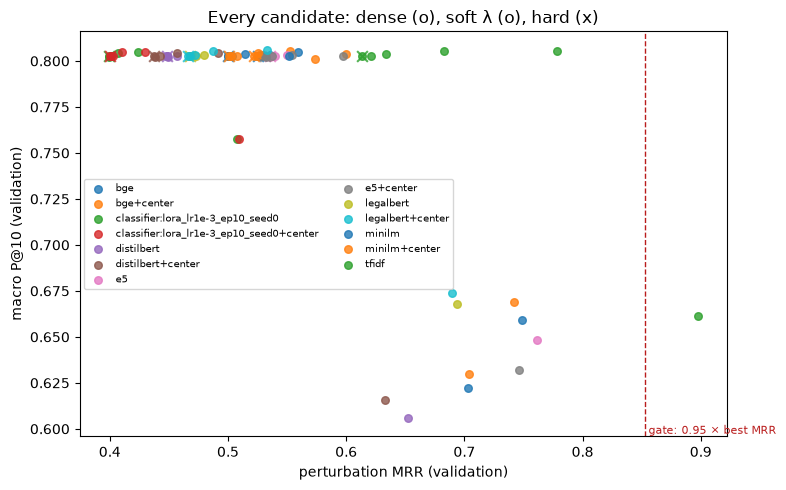

In [11]:
rows = []
for run, m in METRICS.items():
    v = m["val"]
    rows.append(
        {"run": run, "variant": "dense", "p10": v["clause"]["p_at_10_macro"], "mrr": v["perturbation"]["mrr"]}
    )
    for variant, h in v["hybrid"].items():
        rows.append(
            {
                "run": run,
                "variant": variant,
                "p10": h["clause"]["p_at_10_macro"],
                "mrr": h["perturbation"]["mrr"],
            }
        )
grid = pd.DataFrame(rows)
threshold = 0.95 * grid["mrr"].max()
fig, ax = plt.subplots(figsize=(8, 5))
markers = {"dense": "o", "hard": "x"}
for run, g in grid.groupby("run"):
    sc = ax.scatter(g["mrr"], g["p10"], s=30, label=run, marker="o", alpha=0.8)
    for _, r in g[g["variant"] == "hard"].iterrows():
        ax.scatter(r["mrr"], r["p10"], s=60, marker="x", color=sc.get_facecolor()[0])
ax.axvline(threshold, color="#b91c1c", ls="--", lw=1)
ax.text(threshold, ax.get_ylim()[0], " gate: 0.95 × best MRR", color="#b91c1c", fontsize=8, va="bottom")
ax.set(
    xlabel="perturbation MRR (validation)",
    ylabel="macro P@10 (validation)",
    title="Every candidate: dense (o), soft λ (o), hard (x)",
)
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
if not cfg.fast_run:
    fig.savefig(FIGURES / "retrieval_hybrid.png", dpi=150)
grid.pivot(index="run", columns="variant", values=["p10", "mrr"]).loc[ranking.index].round(4)

In [12]:
choice_path = RESULTS / "choice.json"
if choice_path.exists():
    choice = json.loads(choice_path.read_text())
    n = f"{choice['n_gated']} of {choice['n_candidates']}"
    print(
        f"all-pooled lexical rule ({choice['date_utc'][:10]}): {choice['run']} / {choice['variant']} "
        f"(P@10 {choice['p10']:.4f}, perturbation MRR {choice['mrr']:.4f}; "
        f"{n} kept by gate {choice['threshold']:.4f})"
    )
    if "semantic_choice" in choice:
        sc = choice["semantic_choice"]
        nc = choice["nl_choice"]
        print(
            f"semantic clause-to-clause choice: {sc['run']} / {sc['variant']} "
            f"(P@10 {sc['p10']:.4f}, MRR {sc['mrr']:.4f}, NL P@10 {sc['type_names_p_at_10']:.3f}; "
            f"{sc['n_gated']} of {sc['n_candidates']} dense candidates kept by gate {sc['threshold']:.4f})"
        )
        print(
            f"natural-language question choice: {nc['run']} / {nc['variant']} "
            f"(constraint precision {nc['constraint_precision']:.4f}, "
            f"NL P@10 {nc['type_names_p_at_10']:.3f}, "
            f"MRR {nc['mrr']:.4f})"
        )
    if "val_semantic_vs_lexical" in choice:
        cmp_v = choice["val_semantic_vs_lexical"]
        bs_all = cmp_v["bootstrap_macro"]
        low = cmp_v["low_lexical_overlap"]
        bs_low = low["bootstrap_macro"]
        bs_low_m = low["bootstrap_micro"]
        print(
            f"bge+center vs tfidf (all 10 000 val queries): macro P@10 {cmp_v['p_at_10_macro'][0]:.4f} vs "
            f"{cmp_v['p_at_10_macro'][1]:.4f} "
            f"(diff {bs_all['diff']:+.4f}, 95 % CI [{bs_all['low']:+.4f}, {bs_all['high']:+.4f}])"
        )
        print(
            f"low-lexical-overlap quartile (n={low['n_queries']}, "
            f"top-1 TF-IDF cos <= {low['max_tfidf_cos']:.3f}): "
            f"macro P@10 {low['p_at_10_macro'][0]:.4f} vs {low['p_at_10_macro'][1]:.4f} "
            f"(diff {bs_low['diff']:+.4f} [{bs_low['low']:+.4f}, {bs_low['high']:+.4f}]) | "
            f"micro P@10 {low['p_at_10_micro'][0]:.4f} vs {low['p_at_10_micro'][1]:.4f} "
            f"(diff {bs_low_m['diff']:+.4f} [{bs_low_m['low']:+.4f}, {bs_low_m['high']:+.4f}])"
        )
else:
    provisional = retrieval.choose(
        grid.assign(centered=[METRICS[r]["centered"] for r in grid["run"]]).to_dict("records")
    )
    print({k: provisional[k] for k in ("run", "variant", "p10", "mrr", "n_gated", "n_candidates")})

all-pooled lexical rule (2026-10-22): tfidf / dense (P@10 0.6614, perturbation MRR 0.8973; 1 of 78 kept by gate 0.8524)
semantic clause-to-clause choice: bge+center / dense (P@10 0.6689, MRR 0.7422, NL P@10 0.540; 4 of 72 dense candidates kept by gate 0.7232)
natural-language question choice: e5 / dense (constraint precision 0.8619, NL P@10 0.591, MRR 0.7612)
bge+center vs tfidf (all 10 000 val queries): macro P@10 0.6689 vs 0.6614 (diff +0.0076, 95 % CI [+0.0027, +0.0121])
low-lexical-overlap quartile (n=2502, top-1 TF-IDF cos <= 0.401): macro P@10 0.5008 vs 0.4823 (diff +0.0185 [+0.0063, +0.0375]) | micro P@10 0.5986 vs 0.5522 (diff +0.0464 [+0.0368, +0.0560])


→ **Consequence:** every hybrid variant of every encoder lands between 0.80 and 0.81 of macro P@10, with a hard
filter or a soft prior as weak as λ = 0.1: that number is the LoRA classifier's type accuracy, not retrieval. The
price is paid inside the type: perturbation MRR falls from 0.90 to 0.78 (TF-IDF, soft 0.1) and from 0.75 to 0.53
(bge, hard), 8 to 28 points against each encoder's own dense variant, because a wrong predicted type (one
validation query in eight, one in five per type) removes the source clause itself.
- **Why the all-pooled gate picked TF-IDF:** a half-clause shares 100 % of its words with its source clause, so
  pooling lexical TF-IDF (MRR 0.897) with dense encoders (MRR 0.70–0.76) sets the gate at $0.95 \times 0.897 = 0.852$
  and structurally eliminates every dense semantic retriever.
- **Semantic-separated selection (`choose_semantic` and `choose_nl`):** gating among dense encoders ($\text{MRR} \ge
  0.95 \times 0.761 = 0.723$ and zero-shot NL $\text{P@10} \ge 0.50$) keeps 4 candidates (`bge+center`, `bge`, `e5`,
  `e5+center`) and selects **`bge+center` (`dense`)** for clause-to-clause similarity (**0.6689** macro P@10, beating
  TF-IDF's 0.6614 by **+0.76 pts**, 95 % CI [+0.27, +1.21], and by **+1.85 pts macro / +4.64 pts micro** on the
  low-lexical-overlap quartile) and **`e5` (`dense`)** for natural-language questions (**86.2 %** constraint
  precision, **0.591** type-name P@10).

## 6. The test split, once; limits; what the retriever must not be used for

The chosen variant and the dense variant of the same run are the two final models. The test split (10 000
clauses) was read once by `scripts/retrieval.py --final`; the paired bootstrap resamples the same queries for
both.

In [13]:
finals = {run: m["test"] for run, m in METRICS.items() if "test" in m}
if finals:
    run, t = next(iter(finals.items()))
    variants = [k for k, v in t.items() if isinstance(v, dict) and "clause" in v]
    test_table = pd.DataFrame({v: t[v]["clause"] for v in variants}).T
    print(f"{run}: chosen variant {t['chosen_variant']}")
    if "comparison" in t:
        c = t["comparison"]
        verdict = "significant" if c["significant"] else "not significant"
        print(
            f"macro P@10 difference {t['chosen_variant']} - dense: {c['diff']:+.4f}, "
            f"95 % CI [{c['low']:+.4f}, {c['high']:+.4f}] -> {verdict} at 5 %"
        )
    groups = pd.DataFrame({v: {g: s["p_at_10_macro"] for g, s in t[v]["by_group"].items()} for v in variants})
    display(test_table[["p_at_1_macro", "p_at_5_macro", "p_at_10_macro", "mrr", "knn_macro_f1"]].round(4))
    display(groups.round(4))
else:
    print("the test split has not been read yet (run --choose, then --final)")

tfidf: chosen variant dense


,p_at_1_macro,p_at_5_macro,p_at_10_macro,mrr,knn_macro_f1
dense,0.7793,0.7017,0.6584,0.873,0.7366


,dense
band=middle,0.6976
band=head,0.8259
band=tail,0.4260
seen_in_train=False,0.6564
seen_in_train=True,0.7754
truncated=False,0.6584


→ **Consequence:** the chosen configuration holds on the test split: macro P@10 0.658 on the 10 000 test clauses
against 0.661 on validation, MRR 0.873, 10-NN vote macro-F1 0.737 (accuracy 0.826). The same gradient as on validation: head
types 0.83, middle 0.70, tail 0.43; clauses with an exact copy in the bank 0.78, the others 0.66. The chosen variant
is dense, so there is no second final model and no paired test. What the retrieval part leaves open, and would need
its own pre-registration: a dense encoder (e5) as the entry point for *questions*, TF-IDF for *pasted clauses*, and
the type as a manual filter.

**Limits, and what the retriever must not be used for.**
- It retrieves clauses whose *wording* is close, under a proxy that only checks the clause type and two
  within-type tests that no lawyer validated. **It does not establish legal equivalence**: a retrieved clause is
  not a precedent, and a missing clause is not evidence that none exists.
- The bank is LEDGAR: clauses of SEC filings, in English, US-style drafting. Other jurisdictions, languages and
  contract families are out of distribution; the bias audit (part 4) measures how far.
- Clauses longer than the encoder's window (256 or 512 wordpieces) are read truncated; the per-group table of
  section 2 shows what that costs.
- The hybrid inherits every error of the classifier: when it filters hard on a wrong type, the right clauses
  are unreachable. The soft variant is the one the rule allows.
- The constraint grading is a regex: "30 days" matched for the wrong reason counts as a hit.

## Files used

`results/retrieval/<encoder>[+center]/` (configuration, metrics, manifest, `topk_val.npz`, `pred_val.csv`,
`hubs.csv`), `results/retrieval/choice.json`, the chosen run's `topk_test.npz` and `pred_test.csv`;
`reports/retrieval_table.md`. Figures: `reports/figures/retrieval_p10_bands.png`, `retrieval_geometry.png`,
`retrieval_hybrid.png`.